# Search: Solving a Maze Using a Goal-based Agent

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Formulate search problems using key components like initial state, actions, and goal state in a deterministic, fully observable environment.
* Implement the search algorithm BFS for planning paths through mazes.
* Use visualization tools to represent maze paths and support debugging and analysis.

## Instructions

Total Points: Undergrads 10

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file. 


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze. 

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent 
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.** 
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state. 
* **Discrete** means that we have a **finite set of states.** The maze has a finite set 
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The 
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible. 

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [1]:
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

base_url = "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Search/"
download("maze_helper.py", base_url)

mazes = ["small_maze.txt", "large_maze.txt", "open_maze.txt", "empty_maze.txt"]
for maze in mazes:
    download(maze, base_url)

Here is the small example maze:

In [2]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`. 

In [3]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))

Position(0,0): X
Position(8,1): G


A helper function to visualize the maze is also available.

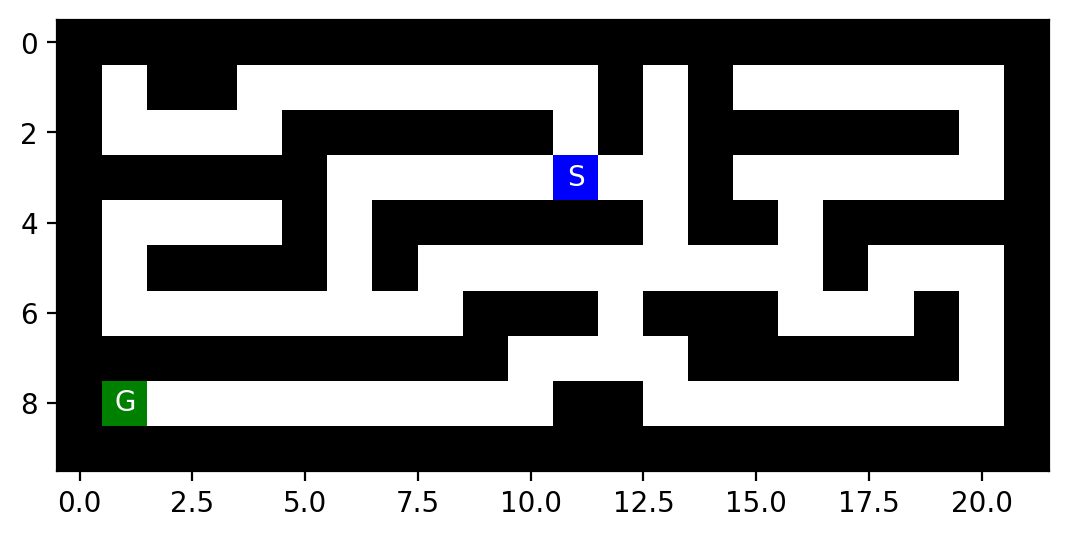

In [4]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [5]:
print("Start location:", mh.find_pos(maze, what = "S"))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [6]:
help(mh)

Help on module maze_helper:

NAME
    maze_helper

DESCRIPTION
    Code for the Maze Assignment by Michael Hahsler
    Usage:
        import maze_helper as mh
        mh.show_some_mazes()

FUNCTIONS
    animate_maze(result, repeat=False)
        (Experimental) Build an animation from a list of mazes.

        Parameters:
            result: a list with the elements path, reached, actions and maze_anim with a list of maze arrays that contain what you want to visualize.
            repeat: if True, the animation will repeat.

    find_pos(maze, what='S')
        Find start/goal in a maze and returns the first one.
        Caution: there is no error checking!

        Parameters:
            maze: a array with characters produced by parse_maze()
            what: the letter to be found ('S' for start and 'G' for goal)

        Returns:
            a tupple (x, y) for the found position.

    look(maze, pos)
        Look at the label of a square with the position as an array of the form (x

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step. 

In [7]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0
        
        # check if plan is completed
        if self.progress >= len(self.plan):        
            raise Exception("Completed Plan. No more planned actions")
        
        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [8]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['E', 'W', 'W', 'S', 'N', 'E', 'E', 'E', 'S', 'S']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [9]:
my_agent = Planning_Agent(maze, mh.find_pos(maze, what = "S"), mh.find_pos(maze, what = "G"), plan_random)

def environment(agent_function, steps):
    for _ in range(steps):
        try:
            agent_function()
        except Exception as e:
            print(f"Agent exception: {e}")

environment(my_agent.act, steps=11)

Planning...
Following plan... step 0: S
Following plan... step 1: N
Following plan... step 2: N
Following plan... step 3: W
Following plan... step 4: N
Following plan... step 5: N
Following plan... step 6: W
Following plan... step 7: S
Following plan... step 8: S
Following plan... step 9: E
Agent exception: Completed Plan. No more planned actions


Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python. 
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [10]:
class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)    # the state; positions are (row,col)
        self.parent = parent     # reference to parent node. None means root node.
        self.action = action     # action used in the transition function (root node has None)
        self.cost = cost         # for uniform cost this is the depth. It is also g(n) for A* search

    def __str__(self):
        return f"Node - pos = {self.pos}; action = {self.action}; cost = {self.cost}"
    
    def get_path_from_root(self):
        """returns nodes on the path from the root to the current node."""
        node = self
        path = [node]
    
        while not node.parent is None:
            node = node.parent
            path.append(node)
        
        path.reverse()
        
        return(path)

If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithm for solving different mazes:
    - Breadth-first search (BFS)

2. Run each of the above algorithms on the 
    - [small maze](small_maze.txt), 
    - [large maze](large_maze.txt), 
    - [open maze](open_maze.txt), and
    - [empty maze](empty_maze.txt).

3. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [2 Points]

Define the components of the search problem:

* Initial state
* Actions
* Transition model
* Goal state
* Path cost

Use verbal descriptions, variables and equations as appropriate. 

*Note:* You can switch the next block from code to Markdown and use formatting.

### Định nghĩa bài toán tìm kiếm

| Thành phần | Định nghĩa |
|---|---|
| **Không gian trạng thái** | Mỗi trạng thái là một ô $s=(r,c)$ không phải tường. $\mathcal{S}=\{(r,c)\mid \text{maze}[r,c]\neq \text{'X'}\}$, $n=|\mathcal{S}|$ |
| **Trạng thái đầu** | $s_0$ = vị trí ô `S` |
| **Hành động** | $\text{ACTIONS}(s)\subseteq\{N,E,S,W\}$: những hướng mà ô kế tiếp không phải tường (mê cung được bao quanh bởi tường nên không bao giờ đi ra ngoài biên) |
| **Mô hình chuyển trạng thái** | $\text{RESULT}((r,c),a)=(r+\Delta r,\;c+\Delta c)$ với $N=(-1,0),\;E=(0,1),\;S=(1,0),\;W=(0,-1)$. Hàm này tất định |
| **Trạng thái đích** | $\text{GOAL-TEST}(s)=\;[\,s\in G\,]$, với $G$ là ô `G` (trong bài này 1 ô) |
| **Chi phí đường đi** | Mỗi bước tốn $c(s,a,s')=1$, nên $g(\text{path})$ = số bước = độ sâu của nút |

Mục tiêu: tìm dãy hành động ngắn nhất từ $s_0$ tới một trạng thái trong $G$.

Give some estimates for the problem size:

* $d$: depth of the optimal solution
* $m$: maximum depth of tree
* $b$: maximum branching factor

Describe how you would determine these values for a given maze.

### Ước lượng kích thước bài toán

| maze | $n$ (số ô trống) | $b$ tối đa | $d$ (độ sâu lời giải tối ưu) | $m$ (độ sâu tối đa của cây BFS) |
|---|---|---|---|---|
| small | 94 | 4 (3 sau khi loại ô cha) | 19 | 19 |
| large | 647 | 4 (3 sau khi loại ô cha) | 210 | 210 |
| open | 684 | 4 (3 sau khi loại ô cha) | 54 | 54 |
| empty | 100 | 4 (3 sau khi loại ô cha) | 14 | 14 |

**Cách xác định:**
* **$d$:** chạy BFS (tối ưu vì mọi bước tốn 1); $d$ là chi phí đường đi tìm được. Cận dưới: khoảng cách Manhattan từ `S` tới `G`.
* **$b$:** với mỗi ô trống đếm số hàng xóm không phải tường (tối đa 4); với cây tìm kiếm, bỏ ô cha nên mỗi nút có nhiều nhất 3 con. Hành lang hẹp có $b\approx1$–$2$, vùng trống $b\approx3$–$4$.
* **$m$:** BFS dừng ngay khi sinh ra đích nên cây có độ sâu đúng bằng $d$ (đo bằng `max_depth` trong code). Nếu duyệt toàn bộ không gian thì $m\le n-1$, vì mỗi trạng thái chỉ xuất hiện một lần trong `reached`.

## Task 2: Breadth-First Search [5 Points]

Implement this simple search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important note** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.


In [11]:
# BFS theo pseudocode trong sách; dùng lại lớp Node đã cho ở trên
from collections import deque

# Bốn hành động; mỗi hành động là (độ thay đổi hàng, độ thay đổi cột)
ACTIONS = {"N": (-1, 0), "E": (0, 1), "S": (1, 0), "W": (0, -1)}


def expand(maze, node):
    """Hàm chuyển trạng thái: sinh các nút con hợp lệ (ô không phải tường). Mỗi bước có chi phí 1."""
    children = []
    for action, (dr, dc) in ACTIONS.items():
        pos = (node.pos[0] + dr, node.pos[1] + dc)
        if mh.look(maze, pos) != "X":
            children.append(Node(pos, node, action, node.cost + 1))
    return children


def bfs_search(maze, start, goal):
    """Breadth-first search (graph search, theo pseudocode trong sách).
    - frontier: hàng đợi FIFO các nút chờ mở rộng
    - reached : dict trạng thái -> nút, để loại đường đi dư thừa (kể cả vòng lặp)
    - Thông tin chỉ nằm trong cây nút / frontier / reached, KHÔNG ghi vào bản đồ.
    Trả về dict gồm path (danh sách nút), actions, số nút mở rộng, reached, độ sâu tối đa."""
    root = Node(start, None, None, 0)
    expanded = 0
    if root.pos == goal:
        return dict(path=[root], actions=[], expanded=0, reached={root.pos: root}, max_depth=0)
    frontier = deque([root])
    reached = {root.pos: root}
    max_depth = 0
    while frontier:
        node = frontier.popleft()
        expanded += 1
        for child in expand(maze, node):
            if child.pos == goal:                       # kiểm tra đích khi SINH nút (early goal test)
                path = child.get_path_from_root()
                return dict(path=path, actions=[n.action for n in path[1:]],
                            expanded=expanded, reached=reached, max_depth=max(max_depth, child.cost))
            if child.pos not in reached:
                reached[child.pos] = child
                frontier.append(child)
                max_depth = max(max_depth, child.cost)
    return dict(path=None, actions=None, expanded=expanded, reached=reached, max_depth=max_depth)


def plan_bfs(maze, start, goal):
    """Hàm lập kế hoạch cho Planning_Agent: trả về dãy hành động (None nếu vô nghiệm)."""
    return bfs_search(maze, start, goal)["actions"]


# Thử nhanh trên small maze: dùng đúng Planning_Agent ở trên với kế hoạch của BFS
s, g = mh.find_pos(maze, "S"), mh.find_pos(maze, "G")
agent = Planning_Agent(maze, s, g, plan_bfs)
first_steps = [agent.act() for _ in range(5)]
print("5 hành động đầu tiên của kế hoạch:", first_steps, "| tổng số bước:", len(agent.plan))


Planning...
Following plan... step 0: E
Following plan... step 1: E
Following plan... step 2: S
Following plan... step 3: S
Following plan... step 4: W
5 hành động đầu tiên của kế hoạch: ['E', 'E', 'S', 'S', 'W'] | tổng số bước: 19


The result of the planning function is a sequence of actions. Kết quả BFS (chạy bởi các ô code bên dưới):

| maze | path length | # of nodes expanded |
|-----------|-----------|------------------|
| small | 19 | 90 |
| large | 210 | 618 |
| open | 54 | 679 |
| empty | 14 | 92 |

Số nút mở rộng tính cả nút cha của đích (nút được mở rộng và sinh ra đích), không tính chính đích. Bảng được sinh ra từ cùng thuật toán với ô code ngay dưới, bạn có thể đối chiếu.

Visualize the found path for each maze. You can look at the `show_maze()` function in [maze_helper.py](maze_helper.py) to see how you can visualize the path.

In [12]:
import pandas as pd
import numpy as np

ex2_mazes = ["small", "large", "open", "empty"]
ex2_results = {}
rows = []
for name in ex2_mazes:
    with open(f"{name}_maze.txt", "r") as f:
        mz = mh.parse_maze(f.read())
    s = tuple(int(x) for x in mh.find_pos(mz, "S")); g = tuple(int(x) for x in mh.find_pos(mz, "G"))
    r = bfs_search(mz, s, g)
    ex2_results[name] = (mz, r)
    # kiểm tra độc lập: chạy lại dãy hành động, không được đâm tường và phải tới G
    pos = s
    for a in r["actions"]:
        pos = (pos[0] + ACTIONS[a][0], pos[1] + ACTIONS[a][1])
        assert mh.look(mz, pos) != "X"
    assert pos == g
    rows.append({"maze": name, "path length": len(r["actions"]), "# of nodes expanded": r["expanded"],
                 "max tree depth": r["max_depth"], "# squares reached": len(r["reached"])})
pd.DataFrame(rows)


,maze,path length,# of nodes expanded,max tree depth,# squares reached
0,small,19,90,19,92
1,large,210,618,210,621
2,open,54,679,54,682
3,empty,14,92,14,95


small maze: path length = 19, nodes expanded = 90, squares reached = 92


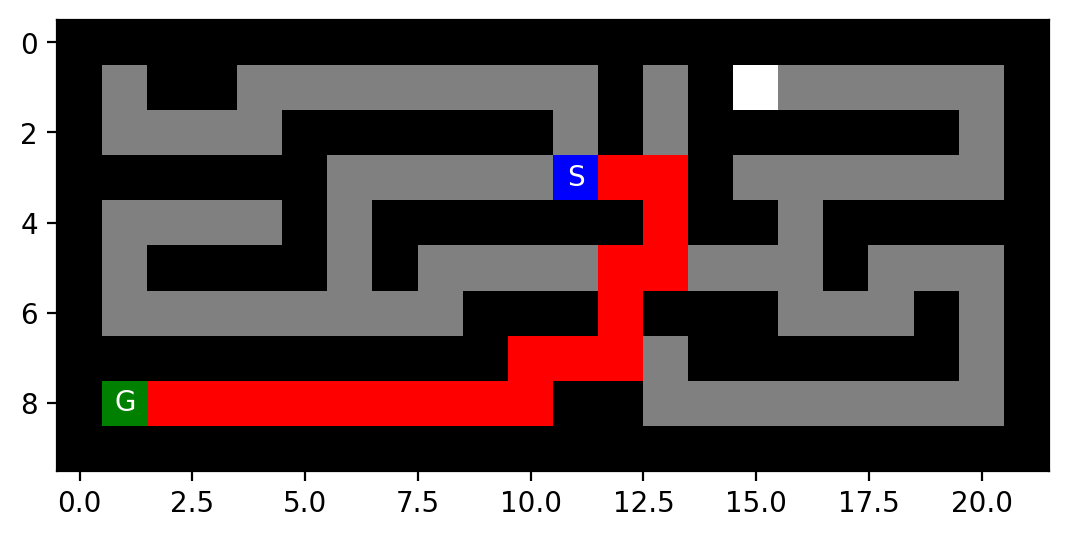

large maze: path length = 210, nodes expanded = 618, squares reached = 621


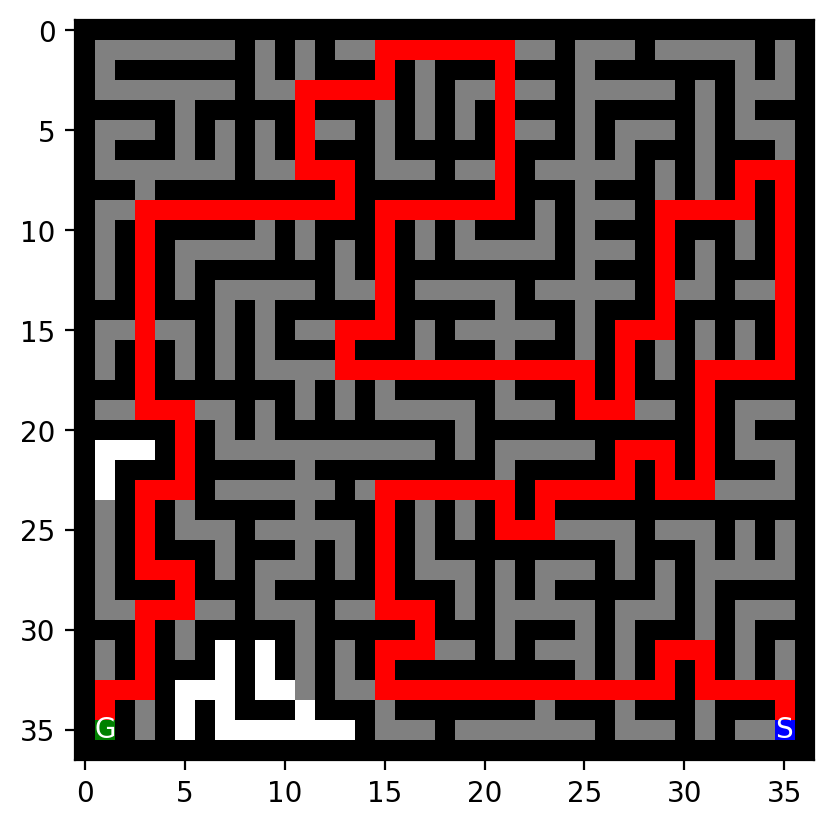

open maze: path length = 54, nodes expanded = 679, squares reached = 682


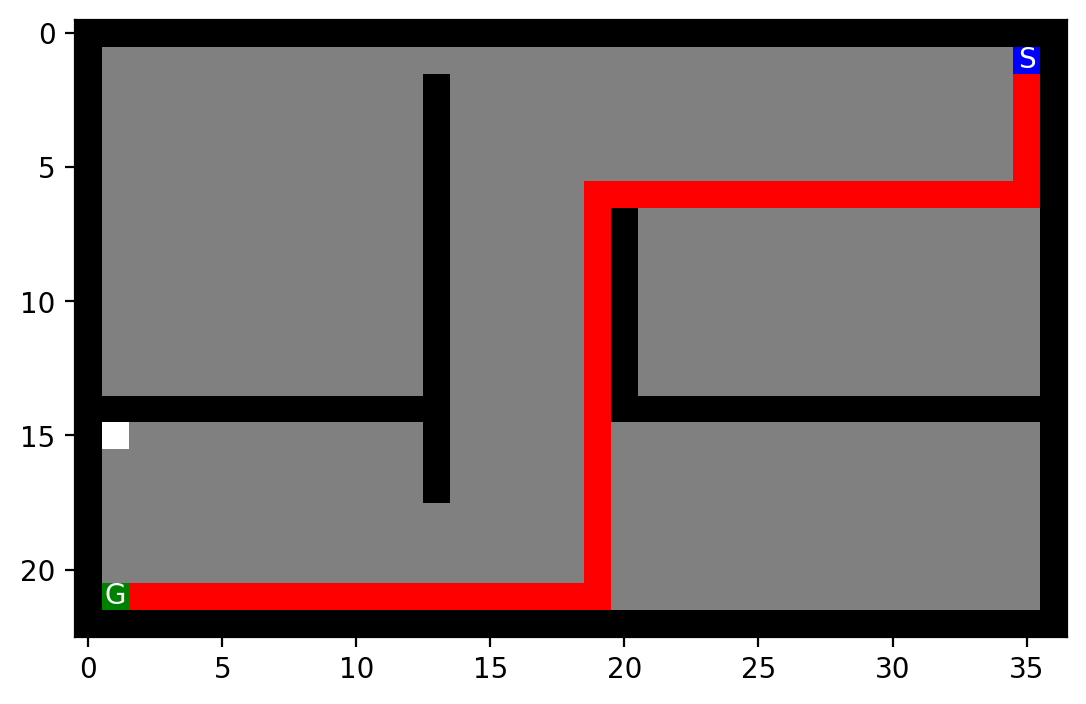

empty maze: path length = 14, nodes expanded = 92, squares reached = 95


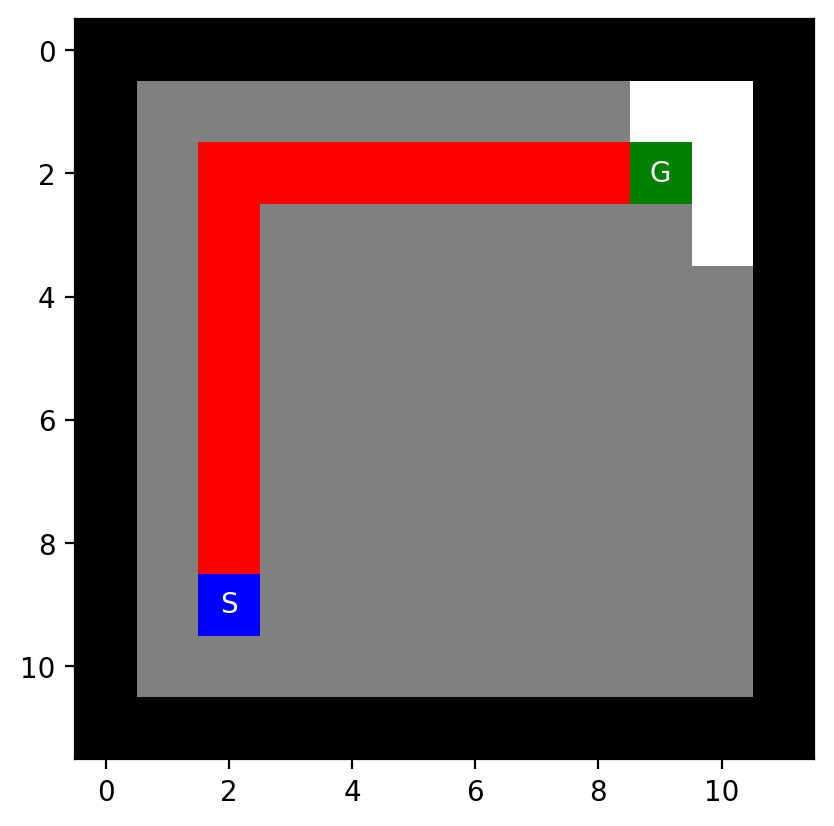

In [13]:
# Hiển thị: ô đã "reached" (đã sinh ra) tô xám '.', đường đi lời giải tô đỏ 'P'. Chỉ sửa BẢN SAO của bản đồ.
for name in ex2_mazes:
    mz, r = ex2_results[name]
    vis = np.copy(mz)
    for pos in r["reached"]:
        if vis[pos] == " ":
            vis[pos] = "."
    for n in r["path"][1:-1]:
        vis[n.pos] = "P"
    print(f"{name} maze: path length = {len(r['actions'])}, nodes expanded = {r['expanded']}, "
          f"squares reached = {len(r['reached'])}")
    mh.show_maze(vis)


# Task 3: Discussion [3 Points] 

Is your implementation complete and optimal? Explain why. What is the time and space complexity of each of **your** implementation?

**Hoàn chỉnh:** có. Không gian trạng thái hữu hạn ($n$ ô) và hệ số nhánh hữu hạn ($\le 4$); nhờ `reached` mỗi ô chỉ vào frontier một lần nên BFS luôn kết thúc: hoặc tìm ra đích, hoặc frontier cạn khi không có lời giải.

**Tối ưu:** có. Mọi hành động có chi phí 1 nên chi phí đường đi bằng độ sâu của nút; FIFO mở rộng các nút theo độ sâu tăng dần nên đích đầu tiên được sinh ra nằm ở độ sâu nhỏ nhất. Thực nghiệm: small = 19, large = 210, open = 54, empty = 14 bước, trùng với khoảng cách ngắn nhất.

**Độ phức tạp:** với $b$ = hệ số nhánh và $d$ = độ sâu của đích nông nhất, thời gian $O(b^d)$ và không gian $O(b^d)$ (frontier và `reached` giữ mọi nút đã sinh). Vì có `reached`, cả hai bị chặn bởi $O(n)$ với $n$ là số ô trống. Ví dụ ở open maze BFS đã phải lưu 682 ô để tìm đường dài 54 bước.

How would the planning improve if you use informed search with A* search and the Euclidean distance to the goal as the heuristic? What would the algorithm do differently?

**A\* với heuristic Euclid:** $h(n)=\sqrt{(r-r_g)^2+(c-c_g)^2}$. Khoảng cách Euclid không bao giờ lớn hơn số bước thực tế trên lưới 4 hướng (thực ra còn nhỏ hơn cả Manhattan) nên $h$ **chấp nhận được** và **nhất quán**, do đó A* vẫn **tối ưu** như BFS.

**Điểm khác:** BFS mở rộng *mọi* nút theo từng lớp độ sâu (một vòng tròn đồng tâm quanh `S`), còn A* luôn mở rộng nút có $f(n)=g(n)+h(n)$ nhỏ nhất, tức là ưu tiên các ô vừa gần `S` vừa hướng về `G`. A* chỉ phải mở rộng các nút có $f(n)\le C^*$ (chi phí tối ưu), nên bỏ qua phần lớn vùng nằm ngược hướng đích. Ở vùng trống như `open` hay `empty`, số nút mở rộng giảm đáng kể (đo bằng Manhattan trong Ex1: open 535 so với 679, empty 63 so với 92). Ở mê cung nhiều tường như `large`, heuristic ít giúp hơn vì đường tối ưu phải vòng xa khỏi đích (Manhattan: A* 549 so với BFS 618). Đổi lại A* cần thêm hàng đợi ưu tiên và tính $h$, mỗi lần mở rộng tốn $O(\log |frontier|)$.

Your BFS implementation works fine to solve small mazes. Why would it not work for larger problems with millions of states and 100s of actions? What algorithm could be used then?

**Vì sao BFS không mở rộng được:** thời gian và đặc biệt là **bộ nhớ** đều tăng theo hàm mũ $O(b^d)$. Với hàng triệu trạng thái và hàng trăm hành động, frontier và `reached` sẽ chứa số nút vượt xa bộ nhớ khả dụng (ví dụ $b=100$, $d=5$ đã là $10^{10}$ nút) trước khi tìm ra đích; bộ nhớ cạn trước khi thời gian cạn.

**Thuật toán thay thế:**
* **A\* (hoặc GBFS) với heuristic tốt** để chỉ mở rộng phần nhỏ của không gian; nếu bộ nhớ vẫn là vấn đề thì dùng các biến thể tiết kiệm bộ nhớ như **IDA\***, RBFS, SMA*.
* **IDS / DFS có giới hạn độ sâu** khi chỉ cần bộ nhớ $O(b\cdot d)$ (đổi lấy thời gian).
* **Tìm kiếm hai chiều** (từ đầu và từ đích) giảm $O(b^d)$ còn $O(b^{d/2})$.
* Khi không gian quá lớn, chấp nhận lời giải gần tối ưu: **beam search** hoặc tìm kiếm cục bộ.